# Ein X-Flare im Bild von SDO

Das Notebook lädt Vollscheibenbilder des Solar Dynamics Observatory zum Maximum des X-Flares vom 3. Oktober 2024 (12:18 UT): AIA in vier Wellenlängen vom extremen UV bis zum UV und ein HMI-Magnetogramm. Es bestimmt die Position des Flares selbst aus dem heißen Plasma in AIA 131 Å, rechnet sie in heliographische Koordinaten um und misst in der aktiven Region NOAA 13842 den magnetischen Fluss, die Polaritätsumkehrlinie und die Flare-Bänder in AIA 1600 Å, deren Lage auf beiden Polaritäten das Standardmodell der Flares prüft.

Wo auf der Sonne fand der Flare statt, und wie hängt das, was man in UV und EUV sieht, mit dem Magnetfeld der aktiven Region zusammen?

#### **Hintergrund**

Das Solar Dynamics Observatory (SDO) der NASA beobachtet die Sonne seit 2010 aus einer geosynchronen Bahn ohne Unterbrechung. Zwei Instrumente liefern die Bilder dieses Notebooks:
- **AIA** (Atmospheric Imaging Assembly) nimmt alle 12 Sekunden Bilder mit 4096 × 4096 Pixeln (0.6″ pro Pixel) in sieben EUV-Kanälen und alle 24 Sekunden in zwei UV-Kanälen auf. Jeder Kanal zeigt Plasma einer anderen Temperatur: 171 Å (Fe IX) Schleifen der ruhigen Korona bei 0.6 Millionen K, 131 Å (Fe XXI im Flare) Plasma bei etwa 10 Millionen K, 304 Å (He II) Chromosphäre und Übergangsregion bei etwa 50 000 K, 1600 Å (C IV und Kontinuum) die obere Photosphäre und untere Chromosphäre.
- **HMI** (Helioseismic and Magnetic Imager) misst aus der Zeeman-Aufspaltung der Eisenlinie bei 6173 Å alle 45 Sekunden die Komponente des Magnetfelds entlang der Sichtlinie in der Photosphäre (0.5″ pro Pixel).

Nach dem Standardmodell der Flares (nach Carmichael, Sturrock, Hirayama, Kopp und Pneuman, kurz CSHKP) liegt über der Polaritätsumkehrlinie einer aktiven Region ein verdrilltes Magnetfeld unter Spannung. Wird es instabil, rekonnektieren Feldlinien in einer Stromschicht in der Korona. Die freigesetzte Energie heizt dort Plasma auf über 10 Millionen K und läuft entlang der neu verbundenen Schleifen nach unten. Wo die Schleifen in der Chromosphäre fußen, leuchten zwei Bänder (Ribbons) auf, je eines auf jeder Seite der Umkehrlinie. Weil jede rekonnektierte Feldlinie ein Ende in der positiven und eines in der negativen Polarität hat, sollte der magnetische Fluss unter beiden Bändern gleich sein.

Die Region NOAA 13842 lag beim Flare nahe der Scheibenmitte, etwas südlich des Äquators. Dort ist die Verkürzung durch die Perspektive klein und das Sichtlinienfeld ein guter Ersatz für das Feld senkrecht zur Oberfläche.

#### **Herleitung**

**1. Von Bildkoordinaten zu heliographischen Koordinaten.** Die Bilder haben helioprojektive Koordinaten $(T_x, T_y)$: Winkel am Himmel, vom Mittelpunkt der Sonnenscheibe aus, mit der Achse $T_y$ zum Nordpol der Sonne. Die Sonne erscheint von der Erde aus unter dem Radius $R_\odot \approx 960''$. Weil sie nur 0.27° groß ist, kann man die Projektion als parallel ansehen (Fehler etwa $R_\odot/D \approx 0.5\,\%$). Ein Punkt der Oberfläche hat dann in Einheiten des Sonnenradius die Koordinaten
$$x = \frac{T_x}{R_\odot}, \qquad y = \frac{T_y}{R_\odot}, \qquad z = \sqrt{1 - x^2 - y^2} ,$$
mit $z$ zum Beobachter. Die Rotationsachse der Sonne ist um den Winkel $B_0$ zum Beobachter geneigt; $B_0$ ist die heliographische Breite der Scheibenmitte und schwankt im Lauf des Jahres zwischen −7.25° und +7.25°. Eine Drehung um die $x$-Achse um $B_0$ gibt Breite $\varphi$ und Länge $\lambda$ im Stonyhurst-System (Länge null zeigt zur Erde):
$$\sin\varphi = y\cos B_0 + z\sin B_0, \qquad \tan\lambda = \frac{x}{z\cos B_0 - y\sin B_0} .$$
In der Scheibenmitte ($x = y = 0$, $z = 1$) ist $\varphi = B_0$, wie es sein muss.

**2. Abstände auf der Sonne.** Eine Bogensekunde entspricht im Abstand $D$ der Länge $D \cdot \pi/648\,000$, bei $D = 1$ AE also 725 km. Ein AIA-Pixel (0.6″) misst 435 km, ein HMI-Pixel (0.5″) 365 km. Abseits der Mitte ist die Oberfläche geneigt: Mit dem Winkel $\theta$ zwischen der Flächennormalen und der Sichtlinie ist
$$\mu = \cos\theta = z = \sqrt{1 - \frac{T_x^2 + T_y^2}{R_\odot^2}} ,$$
und ein Pixel mit der projizierten Fläche $A_p$ deckt die wahre Fläche $A_p/\mu$ ab.

**3. Magnetischer Fluss aus dem Sichtlinienfeld.** HMI misst $B_{los}$, die Komponente entlang der Sichtlinie. In der Photosphäre steht das Feld starker Regionen nahezu senkrecht zur Oberfläche, also gilt $B_{los} \approx B_r\,\mu$. Der Fluss durch die Oberfläche eines Pixels ist dann
$$d\Phi = B_r\,\frac{A_p}{\mu} = \frac{B_{los}\,A_p}{\mu^2}, \qquad \Phi_\pm = \sum_{\text{Pixel mit } B \gtrless 0} \frac{B_{los}\,A_p}{\mu^2} .$$
Die Einheit ist Maxwell: 1 Mx = 1 G cm². Große aktive Regionen tragen einige $10^{22}$ Mx. Weil keine magnetischen Monopole existieren, gleichen sich positiver und negativer Fluss über die ganze Sonne aus; eine einzelne Region kann aber unausgeglichen sein, wenn ein Teil ihres Flusses in weiter entfernten Gebieten fußt.

**4. Die Polaritätsumkehrlinie.** Sie trennt Gebiete positiver und negativer Polarität. Praktisch markiert man Pixel mit $B_{los} > +B_t$ und $B_{los} < -B_t$, vergrößert beide Masken um $k$ Pixel in alle Richtungen (Dilatation) und nimmt die Überlappung. Diese ist ein Band der Breite $2k+1$ Pixel entlang der Linie; die Fläche geteilt durch die Breite schätzt die Länge. Mit einer hohen Schwelle $B_t$ bleiben nur Umkehrlinien zwischen starken, eng benachbarten Polaritäten übrig, wo große Flares bevorzugt entstehen (Schrijver 2007).

**5. Sättigung.** Der CCD-Detektor von AIA kann pro Pixel nur eine bestimmte Ladung halten, der Wandler liefert höchstens 16 383 DN. Darüber läuft die Ladung entlang der Spalte in die Nachbarpixel aus (Blooming), und es entstehen senkrechte Streifen. AIA verkürzt bei Flares die Belichtung in den EUV-Kanälen automatisch, aber nicht in allen Kanälen genug. Gesättigte Pixel geben nur eine untere Grenze der Helligkeit. Damit Bilder mit verschiedenen Belichtungszeiten vergleichbar sind, teilt man durch die Belichtungszeit (DN/s).

#### **Daten**

Die Bilder kommen über `sunpy.net.Fido` aus dem Virtual Solar Observatory (VSO): je ein AIA-Bild der Stufe 1 in 131, 171, 304 und 1600 Å aus den 45 Sekunden ab 12:18:00 UT und das HMI-Magnetogramm derselben Zeit. Zusammen sind das etwa 60 MB; sie landen in `astrodata/sunpy/data` und werden beim nächsten Lauf nicht neu geladen.

Bilder der Stufe 1 sind noch nicht auf ein gemeinsames Pixelgitter gebracht: Jeder Kanal hat eine leicht andere Pixelgröße und Drehung. `sunpy` rechnet über die Weltkoordinaten im Dateikopf, die Kanäle passen damit auf ein bis zwei Bogensekunden zusammen. Das HMI-Bild ist um 180° gedreht gespeichert und wird mit `rotate` nach Norden ausgerichtet.

Die Katalogposition des Flares stammt aus der Heliophysics Event Knowledgebase (HEK). Weil HEK im Oktober 2026 nicht erreichbar war, nutzt das Notebook ersatzweise die Werte einer früheren HEK-Abfrage (Katalog „SSW Latest Events“) und sagt das in der Ausgabe.

In [1]:
# In Colab fehlen sunpy (mit den Teilen net, map, timeseries) und eine Bibliothek zum Lesen von NetCDF4;
# lokal ist meist alles da, und es wird nichts nachinstalliert
import importlib.util, subprocess, sys
missing = []
if importlib.util.find_spec("sunpy") is None:
    missing.append("sunpy[net,map,timeseries]")
if importlib.util.find_spec("netCDF4") is None and importlib.util.find_spec("h5netcdf") is None:
    missing.append("netCDF4")
if missing:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError(f"Es fehlt {', '.join(missing)}; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

In [2]:
import os
from pathlib import Path

# Downloads landen im Ordner "astrodata" neben dem Notebook statt in den Caches im Home-Verzeichnis
# (astropy, sunpy). Das muss vor dem ersten Import von astropy und sunpy passieren; sonst den Kernel neu starten.
ASTRODATA = Path.cwd() / "astrodata"
SUNPY_DIR = ASTRODATA / "sunpy"
for d in (ASTRODATA / "astropy", SUNPY_DIR, ASTRODATA / "goes"):
    d.mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)
(SUNPY_DIR / "sunpyrc").write_text(f"[general]\nworking_dir = {SUNPY_DIR}\n")
os.environ["SUNPY_CONFIGDIR"] = str(SUNPY_DIR)

import socket
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, binary_dilation, label, distance_transform_edt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.time import Time
from astropy.visualization import ImageNormalize, AsinhStretch, LogStretch
import sunpy.map
from sunpy.coordinates import frames
from sunpy.net import Fido, attrs as a, hek

PEAK = Time("2024-10-03T12:18:00")      # Maximum des Flares laut GOES
BOX = 200 * u.arcsec                     # Größe des Ausschnitts um die aktive Region
CHANNELS = {
    131:  "AIA 131 Å: heißes Flare-Plasma, ~10 MK",
    171:  "AIA 171 Å: ruhige Korona, 0.6 MK",
    304:  "AIA 304 Å: Chromosphäre, ~50 000 K",
    1600: "AIA 1600 Å: Flare-Bänder, untere Chromosphäre",
    "HMI": "HMI: Magnetfeld entlang der Sichtlinie",
}

window = a.Time(PEAK, PEAK + 45 * u.s)
wl = a.Wavelength(131 * u.AA) | a.Wavelength(171 * u.AA) | a.Wavelength(304 * u.AA) | a.Wavelength(1600 * u.AA)
search = Fido.search(window, (a.Instrument.aia & wl) | (a.Instrument.hmi & a.Physobs.los_magnetic_field))
files = Fido.fetch(*[block[:1] for block in search], progress=False)

maps = {}
for f in files:
    m = sunpy.map.Map(f)
    if m.detector == "HMI":
        maps["HMI"] = m.rotate(order=1)                 # HMI ist um 180° gedreht gespeichert
    else:
        maps[int(m.wavelength.to_value(u.AA))] = m
maps = {k: maps[k] for k in CHANNELS if k in maps}
print(f"{'Kanal':<6}{'Zeit (UT)':<22}{'Belichtung':>12}{'Pixel':>9}{'Maximum':>10}{'gesättigt':>11}")
for k, m in maps.items():
    expo = f"{m.exposure_time.to_value(u.s):.4f} s" if k != "HMI" else "45 s"
    sat = f"{np.sum(m.data >= 16000)}" if k != "HMI" else "-"
    print(f"{str(k):<6}{m.date.isot[:19]:<22}{expo:>12}{m.scale[0].to_value(u.arcsec / u.pix):>8.3f}″{np.nanmax(m.data):>10.0f}{sat:>11}")
m0 = maps[131]
print(f"\nAbstand SDO-Sonne {m0.dsun.to(u.AU):.4f}, Sonnenradius {m0.rsun_obs:.1f}, B0 = {m0.observer_coordinate.lat.to(u.deg):.2f}")

Kanal Zeit (UT)               Belichtung    Pixel   Maximum  gesättigt
131   2024-10-03T12:18:10       0.0145 s   0.601″      4625          0
171   2024-10-03T12:18:09       1.9996 s   0.599″     16375       8647
304   2024-10-03T12:18:08       0.4158 s   0.600″     11779          0
1600  2024-10-03T12:18:14       2.9013 s   0.609″     16375         73
HMI   2024-10-03T12:18:30           45 s   0.504″      4993          -

Abstand SDO-Sonne 1.0005 AU, Sonnenradius 959.1 arcsec, B0 = 6.58 deg


#### **Reduktion**

##### *1. Die ganze Sonne in fünf Kanälen*

Wie sieht die Sonne im Moment des Flares in den verschiedenen Temperaturbereichen aus, und welche Kanäle sind übersättigt?

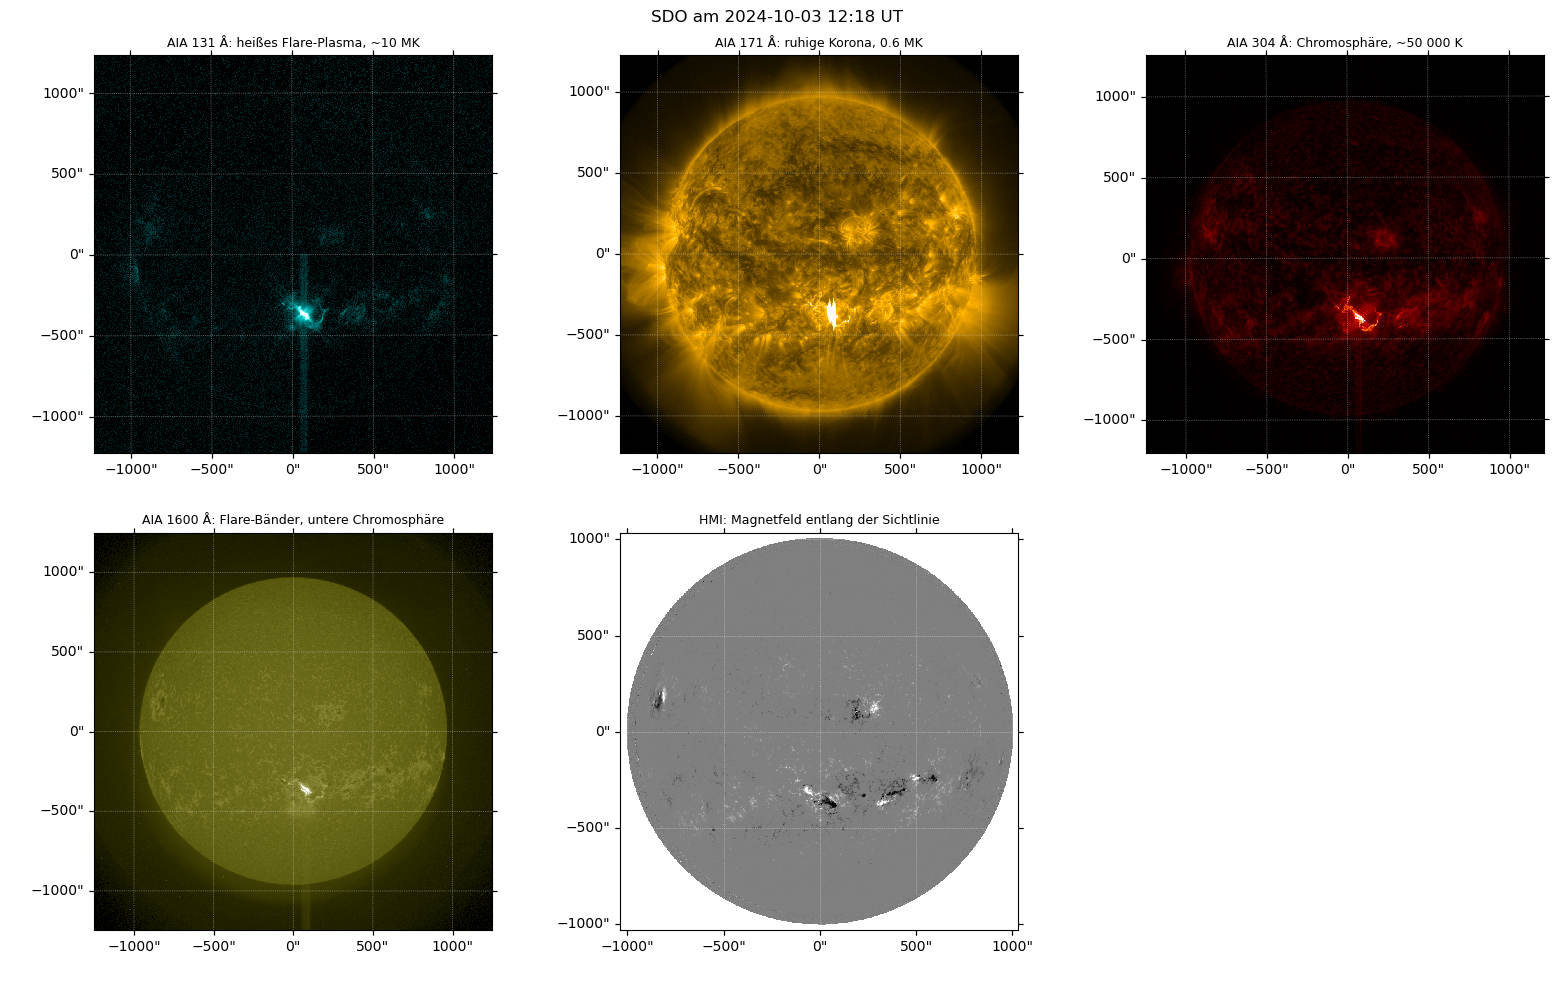

In [3]:
fig = plt.figure(figsize=(16, 10))
for i, (k, m) in enumerate(maps.items()):
    small = m.superpixel([4, 4] * u.pix, func=np.mean)          # 4 × 4 Pixel mitteln: weniger Rauschen, kleineres Bild
    ax = fig.add_subplot(2, 3, i + 1, projection=small)
    if k == "HMI":
        small.plot(axes=ax, cmap="gray", norm=plt.Normalize(-1000, 1000))
    else:
        small = small / m.exposure_time                          # DN/s
        small.plot(axes=ax, norm=ImageNormalize(vmin=0, vmax=np.nanpercentile(small.data, 99.99),
                                                stretch=LogStretch(1000)))
    ax.set_title(CHANNELS[k], fontsize=9)
    ax.coords[0].set_axislabel(" ")
    ax.coords[1].set_axislabel(" ")
fig.suptitle(f"SDO am {PEAK.iso[:16]} UT", y=0.98)
fig.tight_layout()
plt.show()

#### **Eigene Messung**

##### *2. Die Position des Flares*

Wo liegt der hellste Punkt des heißen Plasmas, und in welche heliographische Breite und Länge übersetzt ihn die Formel aus der Herleitung?

In [4]:
SMOOTH = 4                                   # Glättung in Pixeln, damit einzelne helle Pixel nicht zählen
m131 = maps[131]
img = gaussian_filter(np.nan_to_num(m131.data), SMOOTH)
iy, ix = np.unravel_index(np.argmax(img), img.shape)
own = m131.pixel_to_world(ix * u.pix, iy * u.pix)

def to_stonyhurst(Tx, Ty, rsun, B0):
    """Formel aus der Herleitung: parallele Projektion und Drehung um B0."""
    x, y = (Tx / rsun).decompose().value, (Ty / rsun).decompose().value
    z = np.sqrt(1 - x ** 2 - y ** 2)
    lat = np.arcsin(y * np.cos(B0) + z * np.sin(B0))
    lon = np.arctan2(x, z * np.cos(B0) - y * np.sin(B0))
    return np.degrees(lat), np.degrees(lon), z

def label_ns(lat, lon):
    return f"{'N' if lat >= 0 else 'S'}{abs(lat):02.0f}{'W' if lon >= 0 else 'E'}{abs(lon):02.0f}"

B0 = m131.observer_coordinate.lat.to_value(u.rad)
lat_own, lon_own, mu_own = to_stonyhurst(own.Tx, own.Ty, m131.rsun_obs, B0)
hgs = own.transform_to(frames.HeliographicStonyhurst(obstime=m131.date))
km_per_arcsec = (m131.dsun * np.pi / 648000).to_value(u.km)
print(f"Hellster Punkt in AIA 131 Å: Tx = {own.Tx.to_value(u.arcsec):.1f}″, Ty = {own.Ty.to_value(u.arcsec):.1f}″")
print(f"Eigene Formel:  Breite {lat_own:+.2f}°, Länge {lon_own:+.2f}°  → {label_ns(lat_own, lon_own)},  μ = {mu_own:.3f}")
print(f"sunpy:          Breite {hgs.lat.to_value(u.deg):+.2f}°, Länge {hgs.lon.to_value(u.deg):+.2f}°")
print(f"1″ = {km_per_arcsec:.1f} km auf der Sonne")

Hellster Punkt in AIA 131 Å: Tx = 84.1″, Ty = -374.6″
Eigene Formel:  Breite -16.44°, Länge +5.25°  → S16W05,  μ = 0.916
sunpy:          Breite -16.34°, Länge +5.24°
1″ = 725.7 km auf der Sonne


##### *3. Die aktive Region in allen Kanälen*

Wie sieht die Umgebung des Flares aus, und wo liegen die hellen Strukturen relativ zu den starken Magnetfeldern?

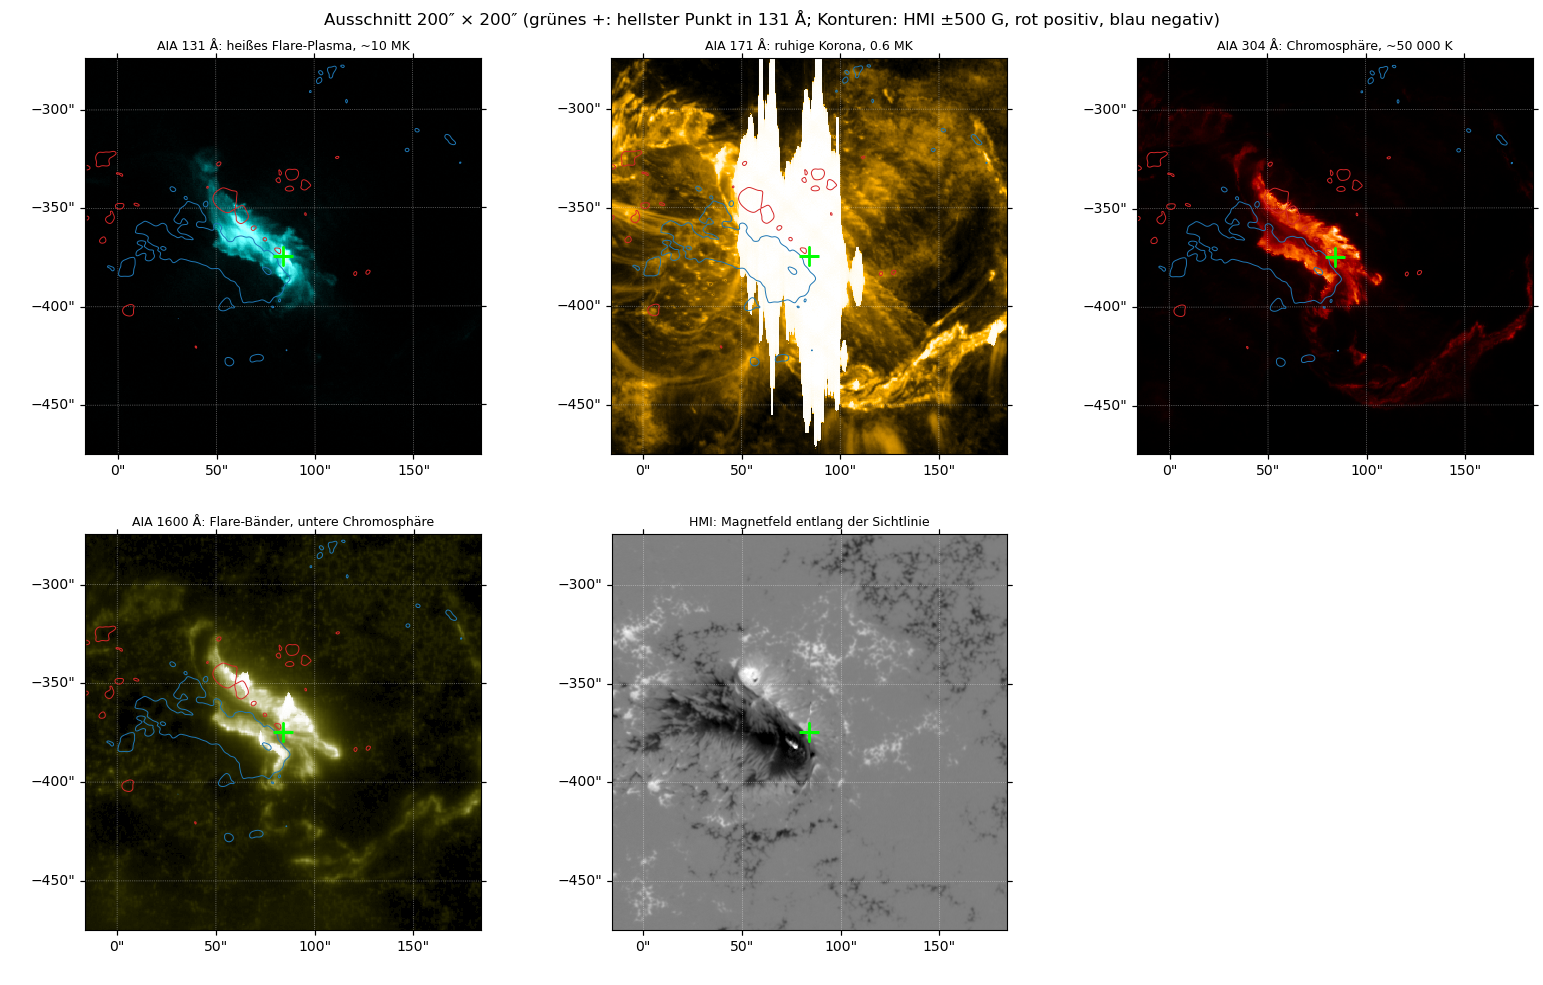

AIA 171: 8540 gesättigte Pixel im Ausschnitt
AIA 1600: 73 gesättigte Pixel im Ausschnitt


In [5]:
bl = SkyCoord(own.Tx - BOX / 2, own.Ty - BOX / 2, frame=own.frame)
tr = SkyCoord(own.Tx + BOX / 2, own.Ty + BOX / 2, frame=own.frame)
subs = {k: m.submap(bl, top_right=tr) for k, m in maps.items()}
hmi = subs["HMI"]
hmi_s = sunpy.map.Map(gaussian_filter(np.nan_to_num(hmi.data), 2), hmi.meta)    # leicht geglättet für Konturen

fig = plt.figure(figsize=(16, 10))
for i, (k, sub) in enumerate(subs.items()):
    ax = fig.add_subplot(2, 3, i + 1, projection=sub)
    if k == "HMI":
        sub.plot(axes=ax, cmap="gray", norm=plt.Normalize(-1500, 1500))
    else:
        sub.plot(axes=ax, norm=ImageNormalize(sub.data, vmin=np.nanpercentile(sub.data, 1),
                                              vmax=np.nanmax(sub.data), stretch=AsinhStretch(0.05)))
        hmi_s.draw_contours([-500, 500] * u.G, axes=ax, colors=["tab:blue", "tab:red"], linewidths=0.7)
    ax.plot_coord(own, "+", color="lime", ms=14, mew=2)
    ax.set_title(CHANNELS[k], fontsize=9)
    ax.coords[0].set_axislabel(" ")
    ax.coords[1].set_axislabel(" ")
fig.suptitle("Ausschnitt 200″ × 200″ (grünes +: hellster Punkt in 131 Å; Konturen: HMI ±500 G, rot positiv, blau negativ)", y=0.98)
fig.tight_layout()
plt.show()
for k in (171, 1600):
    print(f"AIA {k}: {np.sum(subs[k].data >= 16000)} gesättigte Pixel im Ausschnitt")

##### *4. Magnetischer Fluss und Umkehrlinie*

Wie viel magnetischer Fluss steckt in der Region, wie ausgeglichen sind die Polaritäten, und wie lang ist die Umkehrlinie zwischen ihnen?

μ im Ausschnitt 0.848 bis 0.958;  HMI-Pixel 366 km;  Rauschen ≈ 19 G
Region: 7,996 Mm²;  Φ+ = 6.79e+21 Mx,  Φ− = -1.97e+22 Mx,  |Φ| = 2.65e+22 Mx,  Ungleichgewicht (Φ+ + Φ−)/|Φ| = -0.49
Ohne μ-Korrektur wäre |Φ| = 2.26e+22 Mx
Umkehrlinie bei ±150 G: 566 Pixel, Länge ≈ 30 Mm
Umkehrlinie bei ±300 G: 113 Pixel, Länge ≈ 6 Mm
Umkehrlinie bei ±500 G: 0 Pixel, Länge ≈ 0 Mm
Anteil des Flusses der Region innerhalb von 10 Mm um die Umkehrlinie: 47%
Hellster Punkt in 131 Å: B = +382 G, 1.3 Mm von der Umkehrlinie


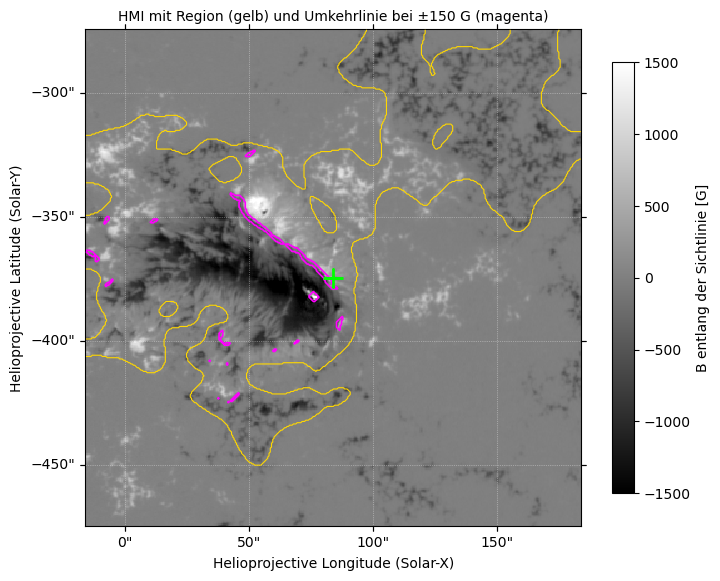

In [6]:
B_T, K_DIL = 150, 3                         # Schwelle [G] und Dilatation [Pixel] für die Umkehrlinie
B = np.nan_to_num(hmi.data)
ny, nx = B.shape
xx_h, yy_h = np.meshgrid(np.arange(nx), np.arange(ny))
c = hmi.pixel_to_world(xx_h * u.pix, yy_h * u.pix)
rsun = hmi.rsun_obs.to_value(u.arcsec)
mu = np.sqrt(np.clip(1 - (c.Tx.to_value(u.arcsec) ** 2 + c.Ty.to_value(u.arcsec) ** 2) / rsun ** 2, 0, 1))
pix_mm = hmi.scale[0].to_value(u.arcsec / u.pix) * km_per_arcsec / 1e3          # Pixelgröße in Mm
A_p = (pix_mm * 1e8) ** 2                                                       # projizierte Pixelfläche [cm²]
noise = np.std(B[np.abs(B) < 50])
print(f"μ im Ausschnitt {mu.min():.3f} bis {mu.max():.3f};  HMI-Pixel {pix_mm * 1e3:.0f} km;  Rauschen ≈ {noise:.0f} G")

# Region: zusammenhängendes Gebiet, in dem das geglättete |B| über 100 G liegt
region_lab, _ = label(gaussian_filter(np.abs(B), 8) > 100)
sizes = np.bincount(region_lab.ravel())
sizes[0] = 0
region = region_lab == sizes.argmax()
flux = B / mu ** 2 * A_p
phi_p, phi_n = flux[region & (B > 0)].sum(), flux[region & (B < 0)].sum()
print(f"Region: {region.sum() * pix_mm ** 2:,.0f} Mm²;  Φ+ = {phi_p:.2e} Mx,  Φ− = {phi_n:.2e} Mx,  "
      f"|Φ| = {phi_p - phi_n:.2e} Mx,  Ungleichgewicht (Φ+ + Φ−)/|Φ| = {(phi_p + phi_n) / (phi_p - phi_n):+.2f}")
print(f"Ohne μ-Korrektur wäre |Φ| = {np.abs(B[region]).sum() * A_p:.2e} Mx")

Bs = gaussian_filter(B, 2)
pil_len = {}
for bt in (B_T, 300, 500):
    pil_t = binary_dilation(Bs > bt, iterations=K_DIL) & binary_dilation(Bs < -bt, iterations=K_DIL)
    pil_len[bt] = pil_t.sum() / (2 * K_DIL + 1) * pix_mm
    print(f"Umkehrlinie bei ±{bt} G: {pil_t.sum()} Pixel, Länge ≈ {pil_len[bt]:.0f} Mm")
pil = binary_dilation(Bs > B_T, iterations=K_DIL) & binary_dilation(Bs < -B_T, iterations=K_DIL)
dist_pil = distance_transform_edt(~pil) * pix_mm                                 # Abstand zur Umkehrlinie [Mm]
near = region & (dist_pil < 10)
print(f"Anteil des Flusses der Region innerhalb von 10 Mm um die Umkehrlinie: {np.abs(flux[near]).sum() / np.abs(flux[region]).sum():.0%}")
p_own = hmi.world_to_pixel(own)
j, i = int(round(p_own.y.value)), int(round(p_own.x.value))
print(f"Hellster Punkt in 131 Å: B = {Bs[j, i]:+.0f} G, {dist_pil[j, i]:.1f} Mm von der Umkehrlinie")

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection=hmi)
hmi.plot(axes=ax, cmap="gray", norm=plt.Normalize(-1500, 1500))
ax.contour(region, levels=[0.5], colors="gold", linewidths=0.8)
ax.contour(pil, levels=[0.5], colors="magenta", linewidths=1.2)
ax.plot_coord(own, "+", color="lime", ms=14, mew=2)
ax.set_title(f"HMI mit Region (gelb) und Umkehrlinie bei ±{B_T} G (magenta)", fontsize=10)
plt.colorbar(ax.images[0], ax=ax, label="B entlang der Sichtlinie [G]", shrink=0.8)
plt.show()

#### **Modell und Fit**

##### *5. Die Flare-Bänder und das Standardmodell*

Liegen die hellen Bänder in AIA 1600 Å auf beiden Seiten der Umkehrlinie in entgegengesetzter Polarität, und tragen sie gleich viel magnetischen Fluss, wie es das Standardmodell verlangt?

Schwelle 3630 DN (1251 DN/s), 7 zusammenhängende Gebiete
 band  pixel  flaeche_Mm2  B_mittel  anteil_pos  anteil_neg         fluss  abstand_PIL_Mm    Tx      Ty     polaritaet
    1     58        12.51     25.59        0.16        0.00  3.540296e+18            7.32 97.26 -392.52 schwaches Feld
    2    758       161.81   -950.05        0.03        0.97 -1.676974e+21            3.89 71.20 -377.93        negativ
    4   1961       416.17    295.10        0.69        0.01  1.319974e+21            5.71 80.36 -363.50        positiv

Bänder in positiver Polarität: 1, 416 Mm², Fluss +1.32e+21 Mx
Bänder in negativer Polarität: 1, 162 Mm², Fluss -1.68e+21 Mx
Verhältnis der Beträge: 0.79


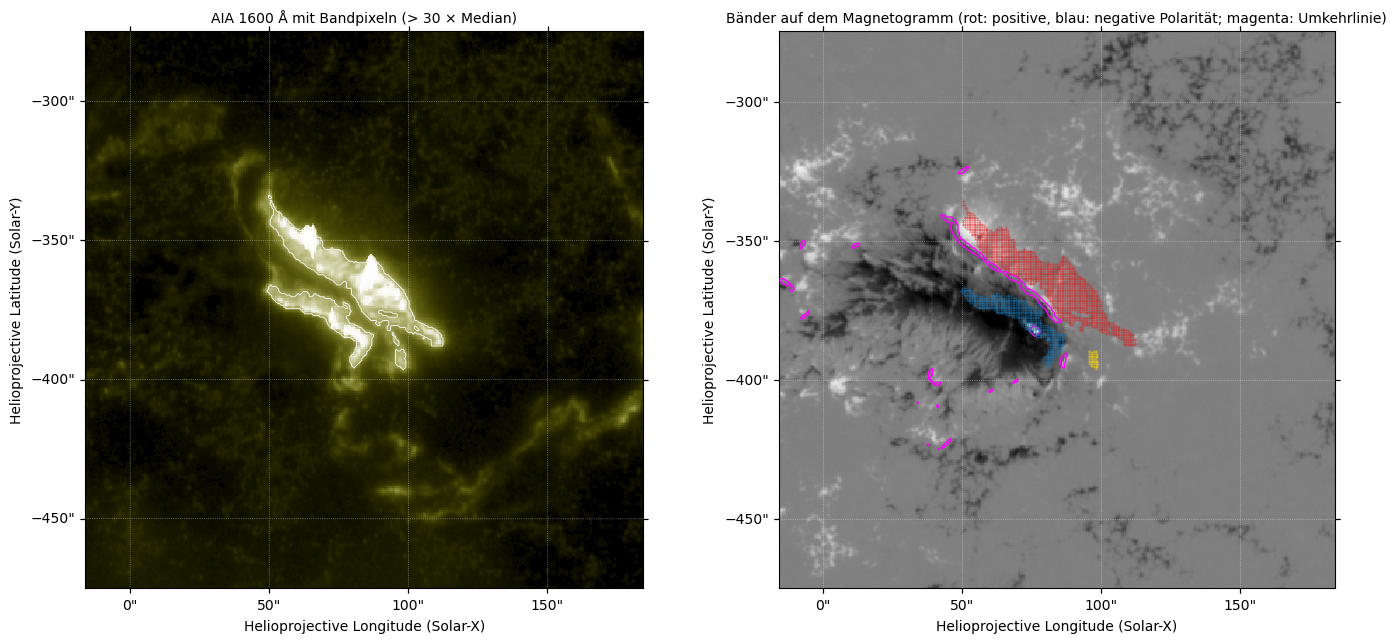

In [7]:
RIBBON_FACTOR = 30                         # Bandpixel: heller als das 30-fache des Medians im Ausschnitt
MIN_PIX = 50                               # kleinere Flecken ignorieren
s1600 = subs[1600]
thr = RIBBON_FACTOR * np.median(s1600.data)
rib_lab, n_rib = label(s1600.data > thr)
A_1600 = (s1600.scale[0].to_value(u.arcsec / u.pix) * km_per_arcsec * 1e5) ** 2       # cm²
print(f"Schwelle {thr:.0f} DN ({thr / maps[1600].exposure_time.to_value(u.s):.0f} DN/s), {n_rib} zusammenhängende Gebiete")

ribbons = []
for k in range(1, n_rib + 1):
    yy, xx = np.nonzero(rib_lab == k)
    if len(yy) < MIN_PIX:
        continue
    w = s1600.pixel_to_world(xx * u.pix, yy * u.pix)
    p = hmi.world_to_pixel(w)                          # dieselben Orte im HMI-Bild
    hi = np.clip(np.round(p.y.value).astype(int), 0, ny - 1)
    hx = np.clip(np.round(p.x.value).astype(int), 0, nx - 1)
    b, m_ = B[hi, hx], mu[hi, hx]
    ribbons.append(dict(band=k, pixel=len(yy), flaeche_Mm2=len(yy) * A_1600 / 1e16 / m_.mean(),
                        B_mittel=b.mean(), anteil_pos=np.mean(b > 100), anteil_neg=np.mean(b < -100),
                        fluss=np.sum(b / m_ ** 2) * A_1600, abstand_PIL_Mm=np.median(dist_pil[hi, hx]),
                        Tx=w.Tx.to_value(u.arcsec).mean(), Ty=w.Ty.to_value(u.arcsec).mean()))
import pandas as pd
rib = pd.DataFrame(ribbons)
# Polarität eines Bandes: mehr als die Hälfte seiner Pixel über +100 G bzw. unter -100 G
rib["polaritaet"] = np.select([rib.anteil_pos > 0.5, rib.anteil_neg > 0.5], ["positiv", "negativ"], "schwaches Feld")
pd.set_option("display.width", 170)
print(rib.round(2).to_string(index=False))
pos, neg = rib[rib.polaritaet == "positiv"], rib[rib.polaritaet == "negativ"]
print(f"\nBänder in positiver Polarität: {len(pos)}, {pos.flaeche_Mm2.sum():.0f} Mm², Fluss {pos.fluss.sum():+.2e} Mx")
print(f"Bänder in negativer Polarität: {len(neg)}, {neg.flaeche_Mm2.sum():.0f} Mm², Fluss {neg.fluss.sum():+.2e} Mx")
print(f"Verhältnis der Beträge: {pos.fluss.sum() / -neg.fluss.sum():.2f}")

fig = plt.figure(figsize=(14, 6.5))
ax = fig.add_subplot(1, 2, 1, projection=s1600)
s1600.plot(axes=ax, norm=ImageNormalize(s1600.data, vmin=np.percentile(s1600.data, 1), vmax=np.nanmax(s1600.data),
                                         stretch=AsinhStretch(0.05)))
ax.contour(rib_lab > 0, levels=[0.5], colors="white", linewidths=0.6)
ax.set_title(f"AIA 1600 Å mit Bandpixeln (> {RIBBON_FACTOR} × Median)", fontsize=10)
ax2 = fig.add_subplot(1, 2, 2, projection=hmi)
hmi.plot(axes=ax2, cmap="gray", norm=plt.Normalize(-1500, 1500))
ax2.contour(pil, levels=[0.5], colors="magenta", linewidths=1)
for _, r in rib.iterrows():
    yy, xx = np.nonzero(rib_lab == r.band)
    w = s1600.pixel_to_world(xx * u.pix, yy * u.pix)
    col = {"positiv": "tab:red", "negativ": "tab:blue"}.get(r.polaritaet, "gold")
    ax2.plot_coord(w, ".", ms=1, color=col, alpha=0.5)
ax2.set_title("Bänder auf dem Magnetogramm (rot: positive, blau: negative Polarität; magenta: Umkehrlinie)", fontsize=10)
fig.tight_layout()
plt.show()

#### **Eigene Messung gegen den Katalog**

##### *6. Position im Vergleich mit HEK*

Wie weit liegt die eigene Position des Flares von der Katalogposition entfernt, und welche Position beschreibt den Flare besser?

In [8]:
HEK_FALLBACK = dict(hpc_x=48.66, hpc_y=-353.99, ar_noaanum=13842, fl_goescls="X9.0",
                    quelle="frühere HEK-Abfrage (SSW Latest Events), weil HEK nicht antwortete")
socket.setdefaulttimeout(30)                # HEK hängt sonst minutenlang, wenn der Dienst gestört ist
try:
    res = hek.HEKClient().search(a.Time(PEAK - 20 * u.min, PEAK + 20 * u.min), a.hek.EventType("FL"),
                                 a.hek.FL.GOESCls >= "X1.0")
    if len(res) == 0:
        raise RuntimeError("keine Einträge")
    r0 = res[0]
    cat = dict(hpc_x=float(r0["hpc_x"]), hpc_y=float(r0["hpc_y"]), ar_noaanum=int(r0["ar_noaanum"]),
               fl_goescls=str(r0["fl_goescls"]), quelle=f"HEK, {r0['frm_name']}")
except Exception as e:
    print(f"HEK nicht verfügbar ({type(e).__name__}: {str(e)[:80]})")
    cat = HEK_FALLBACK
finally:
    socket.setdefaulttimeout(None)

cat_c = SkyCoord(cat["hpc_x"] * u.arcsec, cat["hpc_y"] * u.arcsec, frame=m131.coordinate_frame)
mid = SkyCoord(np.average(rib.Tx, weights=rib.pixel) * u.arcsec, np.average(rib.Ty, weights=rib.pixel) * u.arcsec,
               frame=m131.coordinate_frame)
w_reg = np.abs(flux) * region
cen = SkyCoord(np.sum(c.Tx.to_value(u.arcsec) * w_reg) / w_reg.sum() * u.arcsec,
               np.sum(c.Ty.to_value(u.arcsec) * w_reg) / w_reg.sum() * u.arcsec,
               frame=m131.coordinate_frame)          # 43 s Zeitunterschied zu HMI: vernachlässigbar

print(f"Katalog: {cat['fl_goescls']} in NOAA {cat['ar_noaanum']}  ({cat['quelle']})\n")
print(f"{'Position':<38}{'Tx':>8}{'Ty':>9}{'':>3}{'heliogr.':<10}{'Abstand zu HEK':>16}")
for name, pt in (("HEK", cat_c), ("hellster Punkt AIA 131 Å", own), ("Mitte der Bänder AIA 1600 Å", mid),
                 ("Flussschwerpunkt der Region (HMI)", cen)):
    la, lo, _ = to_stonyhurst(pt.Tx, pt.Ty, m131.rsun_obs, B0)
    d = pt.separation(cat_c).to_value(u.arcsec)
    print(f"{name:<38}{pt.Tx.to_value(u.arcsec):>7.1f}″{pt.Ty.to_value(u.arcsec):>8.1f}″   {label_ns(la, lo):<10}"
          f"{d:>7.1f}″ = {d * km_per_arcsec / 1e3:>4.0f} Mm")
p_hek = hmi.world_to_pixel(cat_c)
jh, ih = int(round(p_hek.y.value)), int(round(p_hek.x.value))
p131 = subs[131].world_to_pixel(cat_c)
v131 = subs[131].data[int(round(p131.y.value)), int(round(p131.x.value))]
print(f"\nAn der HEK-Position: B = {Bs[jh, ih]:+.0f} G, {dist_pil[jh, ih]:.1f} Mm von der Umkehrlinie, "
      f"AIA 131 Å {v131:.0f} DN (Maximum im Ausschnitt {subs[131].data.max():.0f} DN)")

HEK nicht verfügbar (TimeoutError: The read operation timed out)
Katalog: X9.0 in NOAA 13842  (frühere HEK-Abfrage (SSW Latest Events), weil HEK nicht antwortete)

Position                                    Tx       Ty   heliogr.    Abstand zu HEK
HEK                                      48.7″  -354.0″   S15W03        0.0″ =    0 Mm
hellster Punkt AIA 131 Å                 84.1″  -374.6″   S16W05       41.0″ =   30 Mm
Mitte der Bänder AIA 1600 Å              78.2″  -368.0″   S16W05       32.7″ =   24 Mm
Flussschwerpunkt der Region (HMI)        65.0″  -358.5″   S15W04       17.0″ =   12 Mm

An der HEK-Position: B = -91 G, 2.1 Mm von der Umkehrlinie, AIA 131 Å 294 DN (Maximum im Ausschnitt 4625 DN)


Ergebnis beim Lauf vom 2026-10-12 (Bilder von 12:18:08 bis 12:18:30 UT):

- **Sättigung:** AIA lief in 131 Å und 304 Å mit stark verkürzter Belichtung (0.015 s und 0.42 s) und blieb unter der Sättigung. 171 Å lief mit 2.0 s; dort sind 8647 Pixel gesättigt, fast alle im Ausschnitt um den Flare, und die ausgelaufene Ladung bildet senkrechte Streifen. In 1600 Å (2.9 s) sind nur 73 Pixel gesättigt, die Bänder sind sauber messbar.
- **Position:** Der hellste Punkt des heißen Plasmas (131 Å) liegt bei $T_x = 84''$, $T_y = -375''$. Die eigene Formel gibt S16W05 (−16.44°, +5.25°), sunpy −16.34° und +5.24°; die 0.1° Unterschied kommen von der parallelen Projektion. $B_0 = +6.6°$ ist Anfang Oktober fast maximal; ohne diese Drehung läge die Breite um gut 6° daneben. Am Ort des Flares ist $\mu = 0.92$, eine Bogensekunde entspricht 726 km.
- **Fluss der Region:** Die Region (8000 Mm²) trägt $|\Phi| = 2.65\cdot 10^{22}$ Mx, davon $1.97\cdot 10^{22}$ Mx negativ und $0.68\cdot 10^{22}$ Mx positiv (Ungleichgewicht −0.49): Der große negative Fleck dominiert, die zugehörige positive Polarität ist schwächer und weiter verteilt. Ohne die μ-Korrektur wären es 15 % weniger.
- **Umkehrlinie:** Bei ±150 G ist sie etwa 30 Mm lang, bei ±300 G nur noch 6 Mm, bei ±500 G gibt es keine: Die starken Felder beider Polaritäten berühren sich nicht direkt. 47 % des Flusses der Region liegen innerhalb von 10 Mm um die Linie. Der hellste Punkt in 131 Å liegt 1.3 Mm von ihr entfernt.
- **Bänder und Standardmodell:** AIA 1600 Å zeigt zwei Bänder zu beiden Seiten der Umkehrlinie, 3.9 und 5.7 Mm von ihr entfernt. Das südwestliche liegt zu 97 % in negativer Polarität (im Mittel −950 G, 162 Mm²), das nordöstliche zu 69 % in positiver (+295 G, 416 Mm²). Der Fluss unter den Bändern ist $-1.68\cdot 10^{21}$ und $+1.32\cdot 10^{21}$ Mx, das Verhältnis 0.79. Beide Bänder tragen also ähnlich viel Fluss, obwohl eines zweieinhalbmal so groß ist: Das schmale Band liegt über starkem, das breite über schwächerem Feld. Das passt zum Standardmodell. Der Wert gilt nur für den Moment des Maximums; der gesamte rekonnektierte Fluss ist größer.
- **Katalog:** Die HEK antwortete nicht; die Ersatzwerte einer früheren Abfrage geben $48.7''$, $-354.0''$ (S15W03) in NOAA 13842. Das liegt 41″ (30 Mm) vom hellsten Punkt in 131 Å und 33″ (24 Mm) von der Mitte der Bänder entfernt, aber nur 17″ (12 Mm) vom Flussschwerpunkt der Region. An der HEK-Position ist 131 Å mit 294 DN etwa 16-mal schwächer als im Maximum. Die Katalogposition beschreibt also eher die aktive Region als den Ort des Flares.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Schwelle der Bänder:** Setze `RIBBON_FACTOR` auf 15 und auf 60. *(Vorhersage: Die Fläche und der Fluss unter den Bändern ändern sich stark, ihr Verhältnis zwischen den Polaritäten weniger; die Polarität jedes Bandes bleibt.)*
2. **Schwelle der Umkehrlinie:** Setze in Schritt 4 `B_T = 100` und `K_DIL = 5`. *(Vorhersage: Die Linie wird länger und zerfasert, weil auch schwache, gemischte Felder am Rand der Region Umkehrlinien bilden; der Abstand der Bänder zur Linie ändert sich wenig.)*
3. **Magnetogramm vor dem Flare:** Lade das HMI-Bild von 11:30 UT und vergleiche es in den Bändern. *(Vorhersage: Das Feld ist fast gleich; wo es sich an den hellsten Stellen stark unterscheidet, stört der Flare die Messung der Spektrallinie.)*
4. **Ein anderer Kanal:** Ersetze 171 Å durch 94 Å (Fe XVIII, etwa 6 Millionen K). Ist dieser Kanal auch gesättigt?
5. **Ein Flare am Rand:** Setze `PEAK = Time("2024-05-14T16:51:00")` (X8.5 am Westrand). *(Vorhersage: μ wird klein, Fluss und Breite werden unzuverlässig, die Bänder sieht man von der Seite.)*

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Ausrichten der Kanäle:** mit `aiapy` (`update_pointing`, `register`) alle AIA-Bilder auf Stufe 1.5 bringen; dann passen die Kanäle auf Bruchteile einer Bogensekunde.
- **Rekonnektierter Fluss über die Zeit:** alle 1600-Å-Bilder von Beginn bis Ende des Flares (alle 24 Sekunden) laden und die Fläche, die jemals hell war, aufsummieren. Kazachenko et al. (2017) haben so den Fluss für über 3000 Flares gemessen; er wächst mit der Röntgenklasse.
- **Vektormagnetogramme:** Die SHARP-Daten von HMI enthalten alle drei Komponenten des Felds. Daraus folgen elektrische Ströme, Verdrillung und die freie Energie der Region, die Größen, mit denen man Flares vorhersagt.
- **Temperatur des Plasmas:** Aus sechs EUV-Kanälen von AIA lässt sich die Verteilung des Plasmas über die Temperatur (DEM) rekonstruieren und mit der Temperatur aus den GOES-Kanälen vergleichen (`sun_flares.ipynb`).

#### **Referenzen**

- Pesnell, W. D., Thompson, B. J. & Chamberlin, P. C. (2012): *The Solar Dynamics Observatory (SDO)*, Solar Physics 275, 3.
- Lemen, J. R. et al. (2012): *The Atmospheric Imaging Assembly (AIA) on the Solar Dynamics Observatory*, Solar Physics 275, 17.
- Scherrer, P. H. et al. (2012): *The Helioseismic and Magnetic Imager (HMI) Investigation for the Solar Dynamics Observatory*, Solar Physics 275, 207.
- Thompson, W. T. (2006): *Coordinate systems for solar image data*, A&A 449, 791.
- Priest, E. R. & Forbes, T. G. (2002): *The magnetic nature of solar flares*, Astronomy and Astrophysics Review 10, 313.
- Schrijver, C. J. (2007): *A Characteristic Magnetic Field Pattern Associated with All Major Solar Flares and Its Use in Flare Forecasting*, ApJ 655, L117.
- Kazachenko, M. D., Lynch, B. J., Welsch, B. T. & Sun, X. (2017): *A Database of Flare Ribbon Properties from the Solar Dynamics Observatory. I. Reconnection Flux*, ApJ 845, 49.
- The SunPy Community (2020): *The SunPy Project: Open Source Development and Status of the Version 1.0 Core Package*, ApJ 890, 68.